# 02 — Baza modellər

1. Excel pozuntularının sayılması
2. Normallaşdırılmış sorğu qrupuna görə 70/15/15 bölgü (sızma olmasın)
3. Simvol səviyyəli TF-IDF + LR, Linear SVM, RF, Multinomial NB (hiperparametrlər yalnız validation-da)
4. Yalnız uzunluğa əsaslanan model (shortcut yoxlaması)
5. Ən yaxşı modelin confusion matrix-i və səhv nümunələr

Seed = 42. Qrafiklər `figures/` (300 dpi), cədvəllər `results/`, model `models/`.

## 0. Mühit və yollar

In [1]:
import random
import re
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.svm import LinearSVC

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "figures"
RES_DIR = ROOT / "results"
MODEL_DIR = ROOT / "models"
for d in (FIG_DIR, RES_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

COLORS = {0: "#2a78d6", 1: "#eb6834"}
NAMES = {0: "Təmiz (0)", 1: "Zərərli (1)"}
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e5e4e0",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})

def save_fig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=300, bbox_inches="tight")

df = pd.read_csv(PROC_DIR / "clean.csv", keep_default_na=False, dtype={"Query": str, "Label": int})
print(df.shape)

(30902, 2)


## 1. Excel pozuntularının yoxlanması
Dataset Excel-dən keçdiyi üçün bəzi sorğular dəyişib: uzun rəqəmlər elmi formata (`1.94E+15`),
bəzi dəyərlər faizə (`28%`) çevrilib. Bu sətirləri **silmirik**, yalnız sayırıq — hər sinifdə nə qədər olduğunu bilmək
məqalədə datasetin keyfiyyətini təsvir etmək üçün lazımdır.

In [2]:
SCI_RE = re.compile(r"^\s*[-+]?\d+(\.\d+)?[eE][-+]?\d+\s*$")
PCT_RE = re.compile(r"%\s*$")

df["is_sci"] = df["Query"].str.match(SCI_RE)
df["is_pct"] = df["Query"].str.contains(PCT_RE)

artifacts = pd.DataFrame({
    "artifact": ["scientific_notation", "ends_with_percent"],
    "benign_0": [int((df.is_sci & (df.Label == 0)).sum()), int((df.is_pct & (df.Label == 0)).sum())],
    "malicious_1": [int((df.is_sci & (df.Label == 1)).sum()), int((df.is_pct & (df.Label == 1)).sum())],
})
artifacts["total"] = artifacts["benign_0"] + artifacts["malicious_1"]
artifacts["pct_of_dataset"] = (artifacts["total"] / len(df) * 100).round(3)
artifacts.to_csv(RES_DIR / "excel_artifacts.csv", index=False)
display(artifacts)

print("Nümunələr (elmi format):", df.loc[df.is_sci, "Query"].head(8).tolist())
print("Nümunələr (% ilə bitən):", df.loc[df.is_pct, "Query"].head(8).tolist())
df = df.drop(columns=["is_sci", "is_pct"])

,artifact,benign_0,malicious_1,total,pct_of_dataset
0,scientific_notation,642,1,643,2.081
1,ends_with_percent,0,11,11,0.036


Nümunələr (elmi format): ['3.54937E+15', '3.4008E+15', '8.36404E+15', '4.20136E+14', '5.71439E+15', '8.61689E+15', '9.48E+15', '5.83899E+15']
Nümunələr (% ilə bitən): [" or uid like '%", "x' or full_name like '%bob%", " or userid like '%", " or user like '%", " or username like '%", " or uname like '%", "x' OR full_name LIKE '%Bob%", '28%']


## 2. Qrup əsaslı bölgü
Sorğuları normallaşdırırıq (kiçik hərf, ardıcıl boşluqlar bir boşluğa, kənar boşluqlar silinir) və hər
normallaşdırılmış forma üçün qrup ID veririk. `GroupShuffleSplit` əvvəlcə 70% / 30%, sonra qalan 30%-i
50/50 bölür — nəticədə 70/15/15. Bölgü qruplar üzrə aparıldığı üçün sətir sayları dəqiq 70/15/15 olmaya bilər.
Sonda heç bir qrupun iki dəstdə olmadığını `assert` ilə yoxlayırıq.

In [3]:
def normalize(q):
    return re.sub(r"\s+", " ", q.lower()).strip()

df["norm"] = df["Query"].map(normalize)
df["group_id"] = pd.factorize(df["norm"])[0]
print(f"Sətir: {len(df)}, unikal qrup: {df.group_id.nunique()}, "
      f"birdən çox sətri olan qrup: {(df.group_id.value_counts() > 1).sum()}")

gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_idx, rest_idx = next(gss1.split(df, df.Label, df.group_id))
rest = df.iloc[rest_idx]
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
val_idx, test_idx = next(gss2.split(rest, rest.Label, rest.group_id))

train = df.iloc[train_idx].reset_index(drop=True)
val = rest.iloc[val_idx].reset_index(drop=True)
test = rest.iloc[test_idx].reset_index(drop=True)

g = {name: set(part.group_id) for name, part in (("train", train), ("val", val), ("test", test))}
assert not (g["train"] & g["val"]) and not (g["train"] & g["test"]) and not (g["val"] & g["test"])
print("Qrup kəsişməsi yoxdur ✓")

for name, part in (("train", train), ("val", val), ("test", test)):
    part[["Query", "Label", "group_id"]].to_csv(PROC_DIR / f"{name}.csv", index=False, encoding="utf-8")

split_balance = pd.DataFrame([
    {"split": name, "rows": len(part), "share_pct": round(len(part) / len(df) * 100, 2),
     "benign_0": int((part.Label == 0).sum()), "malicious_1": int((part.Label == 1).sum()),
     "malicious_pct": round(part.Label.mean() * 100, 2)}
    for name, part in (("train", train), ("val", val), ("test", test))
]).set_index("split")
split_balance.to_csv(RES_DIR / "02_split_balance.csv")
display(split_balance)

Sətir: 30902, unikal qrup: 30814, birdən çox sətri olan qrup: 84


Qrup kəsişməsi yoxdur ✓


,rows,share_pct,benign_0,malicious_1,malicious_pct
split,,,,,
train,21633,70.01,13686,7947,36.74
val,4634,15.00,2955,1679,36.23
test,4635,15.00,2886,1749,37.73


## 3. Baza modellər: simvol səviyyəli TF-IDF
TF-IDF yalnız **train** dəstində öyrədilir (val/test lüğətə sızmasın). Simvol n-gram 1–5, `sublinear_tf`,
`min_df=2` (yalnız bir dəfə görünən n-gram-lar atılır). Hər model üçün kiçik hiperparametr şəbəkəsi
validation F1-ə görə seçilir; test dəsti bu mərhələdə istifadə olunmur.

In [4]:
X_train, y_train = train["Query"], train["Label"].to_numpy()
X_val, y_val = val["Query"], val["Label"].to_numpy()
X_test, y_test = test["Query"], test["Label"].to_numpy()

vectorizer = TfidfVectorizer(analyzer="char", ngram_range=(1, 5), lowercase=True,
                             sublinear_tf=True, min_df=2, dtype=np.float32)
t0 = time.perf_counter()
Xtr = vectorizer.fit_transform(X_train)
Xva = vectorizer.transform(X_val)
print(f"TF-IDF lüğəti: {len(vectorizer.vocabulary_):,} n-gram, {time.perf_counter() - t0:.1f} s")

GRID = {
    "Logistic Regression": (lambda p: LogisticRegression(C=p, max_iter=2000, random_state=SEED),
                            [0.1, 1, 10, 100]),
    "Linear SVM": (lambda p: LinearSVC(C=p, random_state=SEED), [0.01, 0.1, 1, 10]),
    "Random Forest": (lambda p: RandomForestClassifier(n_estimators=p[0], min_samples_leaf=p[1],
                                                       n_jobs=-1, random_state=SEED),
                      [(200, 1), (200, 2), (400, 1)]),
    "Multinomial NB": (lambda p: MultinomialNB(alpha=p), [0.001, 0.01, 0.1, 1.0]),
}

search_rows, best_params = [], {}
for name, (make, params) in GRID.items():
    best = (-1, None)
    for p in params:
        clf = make(p).fit(Xtr, y_train)
        f1 = f1_score(y_val, clf.predict(Xva))
        search_rows.append({"model": name, "param": str(p), "val_f1": round(f1, 5)})
        if f1 > best[0]:
            best = (f1, p)
    best_params[name] = best[1]
    print(f"{name:20s} ən yaxşı param = {best[1]!s:10s} val F1 = {best[0]:.4f}")

pd.DataFrame(search_rows).to_csv(RES_DIR / "02_val_search.csv", index=False)

TF-IDF lüğəti: 92,815 n-gram, 4.7 s


Logistic Regression  ən yaxşı param = 100        val F1 = 0.9964


Linear SVM           ən yaxşı param = 1          val F1 = 0.9964


Random Forest        ən yaxşı param = (200, 1)   val F1 = 0.9967


Multinomial NB       ən yaxşı param = 0.001      val F1 = 0.9340


Seçilmiş parametrlərlə hər modeli **train** üzərində yenidən öyrədib, vektorlaşdırıcı ilə birlikdə tam
pipeline kimi saxlayırıq (xam sorğu → ehtimal). Metrikalar:

- accuracy, precision, recall, F1 (müsbət sinif = zərərli)
- ROC-AUC (`predict_proba` və ya Linear SVM üçün `decision_function`)
- FPR = FP / (FP + TN) — təmiz sorğuların neçə faizi səhvən bloklanır
- gecikmə: test dəstindən 1000 sorğu **bir-bir** pipeline-dan keçirilir (vektorlaşdırma + proqnoz),
  orta vaxt ms ilə — middleware ssenarisinə ən yaxın ölçü. Əvvəlcə 50 sorğu ilə "isinmə" edilir.

In [5]:
def score(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

def latency_ms(model, queries, n=1000, warmup=50):
    qs = queries.sample(n=min(n, len(queries)), random_state=SEED).tolist()
    for q in qs[:warmup]:
        model.predict([q])
    t0 = time.perf_counter()
    for q in qs:
        model.predict([q])
    return (time.perf_counter() - t0) / len(qs) * 1000

def evaluate(name, model, X, y, extra=None):
    pred = model.predict(X)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    row = {
        "model": name,
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred),
        "f1": f1_score(y, pred),
        "roc_auc": roc_auc_score(y, score(model, X)),
        "fpr": fp / (fp + tn),
        "tp": tp, "fp": fp, "tn": tn, "fn": fn,
        "latency_ms": latency_ms(model, X),
    }
    row.update(extra or {})
    return row

pipelines, results = {}, []
for name, (make, _) in GRID.items():
    pipe = Pipeline([("tfidf", vectorizer), ("clf", make(best_params[name]))])
    pipe.named_steps["clf"].fit(Xtr, y_train)  # vektorlaşdırıcı artıq train-də öyrədilib
    pipelines[name] = pipe
    val_f1 = f1_score(y_val, pipe.predict(X_val))
    results.append(evaluate(name, pipe, X_test, y_test,
                            {"features": "char TF-IDF 1-5", "best_param": str(best_params[name]),
                             "val_f1": val_f1}))
    print(f"{name} hazırdır")

Logistic Regression hazırdır


Linear SVM hazırdır


Random Forest hazırdır


Multinomial NB hazırdır


## 4. Uzunluq yoxlaması
Analizdə təmiz sorğuların median uzunluğu 35, zərərlilərin 85 simvol idi. Əgər yalnız uzunluğa baxan model
yüksək nəticə göstərsə, bu o deməkdir ki, dataset modelə "uzundursa zərərlidir" kimi qısa yol (shortcut) verir.
Xüsusiyyət: `log(1 + uzunluq)` (paylanma sağa əyri olduğu üçün), standartlaşdırma + Logistic Regression.

In [6]:
def length_feature(X):
    return np.log1p(np.asarray([len(q) for q in X], dtype=float)).reshape(-1, 1)

length_model = make_pipeline(FunctionTransformer(length_feature), StandardScaler(),
                             LogisticRegression(random_state=SEED))
length_model.fit(X_train, y_train)
val_f1_len = f1_score(y_val, length_model.predict(X_val))
results.append(evaluate("Length-only LR", length_model, X_test, y_test,
                        {"features": "log(1+length)", "best_param": "-", "val_f1": val_f1_len}))

coef = length_model[-1].coef_[0, 0]
intercept = length_model[-1].intercept_[0]
scaler = length_model[1]
thr_log = scaler.mean_[0] - intercept / coef * scaler.scale_[0]
print(f"Uzunluq modelinin qərar həddi: ≈ {np.expm1(thr_log):.0f} simvoldan uzun sorğu → zərərli")

Uzunluq modelinin qərar həddi: ≈ 72 simvoldan uzun sorğu → zərərli


## Nəticə cədvəli
Bütün metrikalar test dəstindədir. "Ən yaxşı model" **validation F1**-ə görə seçilir (test-ə görə seçmək
test dəstini model seçiminə qatardı).

In [7]:
res = pd.DataFrame(results)
metric_cols = ["accuracy", "precision", "recall", "f1", "roc_auc", "fpr", "val_f1"]
res[metric_cols] = res[metric_cols].astype(float).round(4)
res["latency_ms"] = res["latency_ms"].astype(float).round(4)
res = res[["model", "features", "best_param", "accuracy", "precision", "recall", "f1", "roc_auc", "fpr",
           "latency_ms", "val_f1", "tp", "fp", "tn", "fn"]]
res.to_csv(RES_DIR / "baseline_results.csv", index=False)
display(res)

best_name = res[res.model != "Length-only LR"].sort_values("val_f1", ascending=False).iloc[0]["model"]
best_model = pipelines[best_name]
joblib.dump(best_model, MODEL_DIR / "best_baseline.joblib", compress=3)
print(f"Ən yaxşı model (val F1): {best_name} → models/best_baseline.joblib")

,model,features,best_param,accuracy,precision,recall,f1,roc_auc,fpr,latency_ms,val_f1,tp,fp,tn,fn
0,Logistic Regression,char TF-IDF 1-5,100,0.9972,1.0000,0.9926,0.9963,0.9987,0.0000,1.0639,0.9964,1736,0,2886,13
1,Linear SVM,char TF-IDF 1-5,1,0.9972,1.0000,0.9926,0.9963,0.9989,0.0000,1.0207,0.9964,1736,0,2886,13
2,Random Forest,char TF-IDF 1-5,"(200, 1)",0.9968,1.0000,0.9914,0.9957,0.9996,0.0000,50.0750,0.9967,1734,0,2886,15
3,Multinomial NB,char TF-IDF 1-5,0.001,0.9592,0.9105,0.9891,0.9482,0.9984,0.0589,1.9067,0.9340,1730,170,2716,19
4,Length-only LR,log(1+length),-,0.7650,0.7364,0.5878,0.6537,0.8240,0.1275,0.4608,0.6556,1028,368,2518,721


Ən yaxşı model (val F1): Random Forest → models/best_baseline.joblib


## ROC əyriləri
Bütün modellər eyni oxda; uzunluq modeli qırıq xətlə göstərilir.

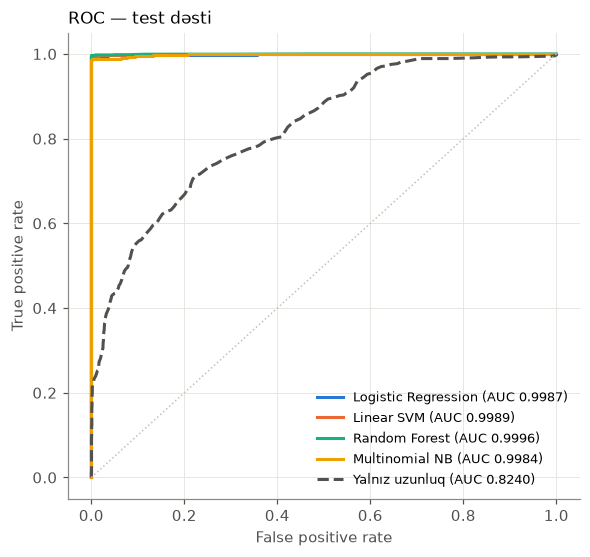

In [8]:
ROC_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
fig, ax = plt.subplots(figsize=(6, 5.5))
for (name, pipe), c in zip(pipelines.items(), ROC_COLORS):
    fpr, tpr, _ = roc_curve(y_test, score(pipe, X_test))
    auc = res.loc[res.model == name, "roc_auc"].iloc[0]
    ax.plot(fpr, tpr, color=c, linewidth=2, label=f"{name} (AUC {auc:.4f})")
fpr, tpr, _ = roc_curve(y_test, score(length_model, X_test))
auc = res.loc[res.model == "Length-only LR", "roc_auc"].iloc[0]
ax.plot(fpr, tpr, color="#52514e", linewidth=2, linestyle="--", label=f"Yalnız uzunluq (AUC {auc:.4f})")
ax.plot([0, 1], [0, 1], color="#c3c2b7", linewidth=1, linestyle=":")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC — test dəsti", loc="left", fontsize=11)
ax.legend(frameon=False, loc="lower right", fontsize=8.5)
save_fig(fig, "02_roc_curves.png")
plt.show()

## 5. Ən yaxşı modelin confusion matrix-i və səhvləri

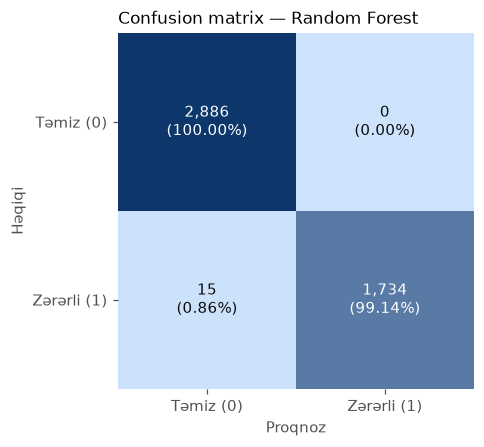

In [9]:
pred = best_model.predict(X_test)
cm = confusion_matrix(y_test, pred, labels=[0, 1])
cmap = LinearSegmentedColormap.from_list("blue_seq", ["#cde2fb", "#0d366b"])

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.imshow(cm, cmap=cmap)
ax.grid(False)
for i in range(2):
    for j in range(2):
        val = cm[i, j]
        dark = val > cm.max() / 2
        ax.text(j, i, f"{val:,}\n({val / cm[i].sum() * 100:.2f}%)", ha="center", va="center",
                fontsize=10, color="white" if dark else "#0b0b0b")
ax.set_xticks([0, 1], [NAMES[0], NAMES[1]])
ax.set_yticks([0, 1], [NAMES[0], NAMES[1]])
ax.set_xlabel("Proqnoz")
ax.set_ylabel("Həqiqi")
ax.set_title(f"Confusion matrix — {best_name}", loc="left", fontsize=11)
for s in ax.spines.values():
    s.set_visible(False)
save_fig(fig, "02_confusion_matrix_best.png")
plt.show()

Səhv təsnif olunmuş nümunələr: **false positive** (təmiz, amma zərərli sayılıb) və **false negative**
(zərərli, amma buraxılıb), hər birindən ən çoxu 15. Ehtimal/skor ilə birlikdə göstərilir və
`results/02_misclassified.csv` faylına yazılır.

In [10]:
test_out = test[["Query", "Label"]].copy()
test_out["pred"] = pred
test_out["score"] = score(best_model, X_test)
test_out["length"] = test_out["Query"].str.len()

fp_rows = test_out[(test_out.Label == 0) & (test_out.pred == 1)].sort_values("score", ascending=False).head(15)
fn_rows = test_out[(test_out.Label == 1) & (test_out.pred == 0)].sort_values("score").head(15)
pd.concat([fp_rows.assign(error="FP"), fn_rows.assign(error="FN")]).to_csv(
    RES_DIR / "02_misclassified.csv", index=False)

for title, rows in (("FALSE POSITIVE (təmiz → zərərli)", fp_rows), ("FALSE NEGATIVE (zərərli → təmiz)", fn_rows)):
    print(f"===== {title}: {len(rows)} göstərilir =====")
    for _, r in rows.iterrows():
        print(f"  skor={r.score:+.3f}  len={r.length:4d}  {r.Query[:160]!r}")
    print()

===== FALSE POSITIVE (təmiz → zərərli): 0 göstərilir =====

===== FALSE NEGATIVE (zərərli → təmiz): 15 göstərilir =====
  skor=+0.005  len=   8  '3.10E+17'
  skor=+0.025  len=   8  'truncate'
  skor=+0.030  len=   5  'PRINT'
  skor=+0.050  len=  46  'grant connect to name; grant resource to name;'
  skor=+0.130  len=  13  '# from wapiti'
  skor=+0.150  len=   2  'or'
  skor=+0.290  len=   3  '29%'
  skor=+0.320  len=  40  "create user name identified by 'pass123'"
  skor=+0.410  len=  50  '0x730065006c0065006300740020004000400076006500 ...'
  skor=+0.415  len=  40  '@var select @var as var into temp end --'
  skor=+0.460  len=  14  '1\'qhfy<\'">utwq'
  skor=+0.475  len=  36  "exec sp_addlogin 'name' , 'password'"
  skor=+0.485  len=  17  '; exec xp_regread'
  skor=+0.485  len=  18  'or   (  EXISTS  ) '
  skor=+0.495  len=  55  " union select 1,load_file  (  '/etc/passwd'  )  ,1,1,1;"

